# DM-2 : Boosting et cartes de saillance

In [190]:
import numpy as np
import matplotlib.pyplot as plt
import os
import pandas as pd
seed =42

## 0. Import du dataset MNIST

Pour AdaBoost, il n'est pas vraiment nécessaire de normaliser. Cependant, cela devient nécessaire pour le perceptron. Nous divisons donc X par 255.

Par ailleurs, nous n'utilisons pas StandardScaler pour éviter d'amplifier le bruit du fond (variance presque nulle) et éviter toute fuite de données de test à train.

In [191]:
from sklearn.datasets import fetch_openml

X, y = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
X = X / 255.0
y = y.astype(int)

(70000, 784) (70000,)


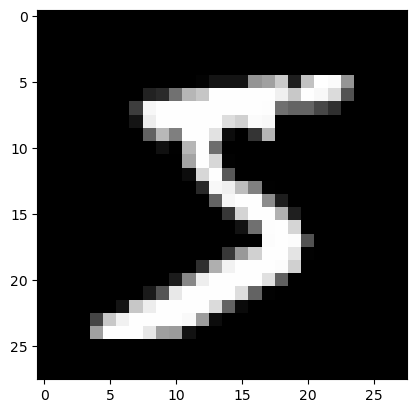

In [109]:
print(X.shape, y.shape)
plt.imshow(X[0, :].reshape(28, 28), cmap="Greys_r")

In [ ]:
np.unique_counts(y)

- Le jeu de données comprend 70000 images aplaties de taille (1, 784) ((28,28) à l'origine).
- Ce sont des chiffres manuscrits entre 0 et 9, les classes peuvent être considérées étant équilibrées.

## 1. Utilisation d’un algorithme de boosting sur de la reconnaissance de chiﬀres manuscrits

Séparation du dataset en set d'entrainnement et de test. \
75 % en entrainnement et 25% en test, car nous avons un grand nombre d'images.

In [192]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=seed)

### A. Première modélisation

Première modelisation avec Adaboost :
- Abre de décision (profondeur maximal de 20)
- nombre d'estimateur : 20
- learning rate : 0.5 \
\
Nous avons repris les hyperparamètres du site Medium donné dans le sujet du DM.

In [153]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

Tree_adaboost = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=20),
                                  n_estimators=20,
                                  learning_rate=0.5,
                                  random_state=seed)

Tree_adaboost.fit(X_train, y_train)

Tree_adaboost_score = Tree_adaboost.score(X_test, y_test)
print(f"AdaBoost score: {Tree_adaboost_score}")

KeyboardInterrupt: 

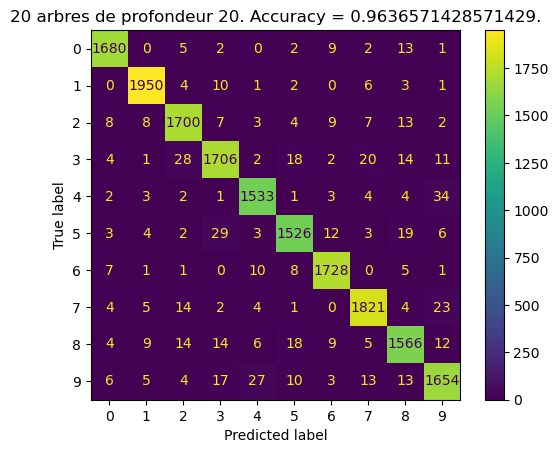

In [112]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay

cm_Tree_adaboost = confusion_matrix(y_test, Tree_adaboost.predict(X_test))
cm_Tree_adaboost_disp = ConfusionMatrixDisplay(cm_Tree_adaboost)
cm_Tree_adaboost_disp.plot()
cm_Tree_adaboost_disp.ax_.set_title(f"20 arbres de profondeur 20. Accuracy = {Tree_adaboost_score}.")
plt.savefig("images/cm_AdaBoost/cm_First_Tree_adaboost.png", dpi=300, bbox_inches="tight")

<img src="images/cm_AdaBoost/cm_First_Tree_adaboost.png" alt= "Matrice de confusion décision stump" width="500">

Avec ce premier modèle, nous obtenons un taux de bonne classification de 0,9637 en test. La matrice de confusion montre de bons résultats avec une majorité de bons classements, surtout pour les 1.

La matrice de confusion se lit par ligne : chaque ligne correspond à la vraie classe et chaque colonne à la classe prédite. La grande majorité des images se trouve sur la diagonale.

- les mieux reconnus sont les 1, les 6 et les 0 ;
- les moins bien reconnus sont les 9, les 8 et les 3. \
\
Les principales confusions sont :

- entre les 4 et les 9, dans les deux sens (27 + 34 = 61 erreurs), un 4 fermé en haut ressemblant à un 9 ;
- des 3 prédits comme des 2 (35 erreurs) ;
- des 5 prédits comme des 3 (47 erreurs), ces deux chiffres partagent effectivement la même boucle inférieure.

### B. Cross-validation en variant les classifier faibles

Dans cette section, nous testons différentes conbinaisons de nombre et de type d'apprennants faibles, avec l'algorithme AdaBoost.

Stratification pour la cross-validation. Nous nous assurons qu'il y ait la même proportion d'exemples de chaque classe dans les set d'entrainement et de validation.

In [193]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
folds = skf.split(X_train, y_train)

Réglage des paramètres à tester pour la cross validation. \
Nous testons des arbres de profondeur maxiamale de 1, 2, 3, 5, 20.
Nous testons les nombres d'estimateurs suivants : 1, 2, 5, 10, 20, 50.

In [194]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d3": DecisionTreeClassifier(max_depth=3),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=seed)}

params = {"n_estimators" : [1, 2, 5, 10, 20, 50]}

Nous réalisons la cross-validation : \
*Attention, le temps de calcul est important : 1h35 sur mon ordinateur.*

In [196]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay

n_estimators_list = sorted(params["n_estimators"])

n_cols = 3
n_rows = int(np.ceil(len(n_estimators_list) / n_cols))

results = []

for estimator_name, estimator in estimators.items():
    # Figure avec une matrice de confusion par valeur de n_estimators
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
    axes = np.ravel(axes)

    for ax, n_est in zip(axes, n_estimators_list):
        model = AdaBoostClassifier(estimator=estimator,
                                   n_estimators=n_est,
                                   random_state=seed)

        # Cross-val : une seule passe par configuration.
        # y_pred_cv contient, pour chaque individu, la prédiction du fold
        # où il était en validation (prédictions "out-of-fold").
        y_pred_cv = cross_val_predict(model, X_train, y_train,
                                      cv=skf, n_jobs=-1)
        acc_cv = accuracy_score(y_train, y_pred_cv)

        # Résultats de la cross-val dans le dataframe
        results.append({"estimator": estimator_name,
                        "n_estimators": n_est,
                        "accuracy": acc_cv})

        # Matrice de confusion à partir de ces mêmes prédictions CV
        cm = confusion_matrix(y_train, y_pred_cv)
        disp = ConfusionMatrixDisplay(cm)
        disp.plot(ax=ax, colorbar=False)
        ax.set_title(f"n_estimators = {n_est}\nacc CV = {acc_cv:.3f}")
    print(results)

    fig.suptitle(f"AdaBoost — {estimator_name}", fontsize=16)
    fig.tight_layout()
    fig.savefig(f"images/cm_AdaBoost/cm_{estimator_name}_all.png",
                dpi=300, bbox_inches="tight")
    plt.close(fig)

df_results = pd.DataFrame(results)
print(df_results)

[{'estimator': 'stump', 'n_estimators': 1, 'accuracy': 0.19706666666666667}, {'estimator': 'stump', 'n_estimators': 2, 'accuracy': 0.18420952380952382}, {'estimator': 'stump', 'n_estimators': 5, 'accuracy': 0.2172}, {'estimator': 'stump', 'n_estimators': 10, 'accuracy': 0.2713904761904762}, {'estimator': 'stump', 'n_estimators': 20, 'accuracy': 0.49241904761904765}, {'estimator': 'stump', 'n_estimators': 50, 'accuracy': 0.6373142857142857}]
[{'estimator': 'stump', 'n_estimators': 1, 'accuracy': 0.19706666666666667}, {'estimator': 'stump', 'n_estimators': 2, 'accuracy': 0.18420952380952382}, {'estimator': 'stump', 'n_estimators': 5, 'accuracy': 0.2172}, {'estimator': 'stump', 'n_estimators': 10, 'accuracy': 0.2713904761904762}, {'estimator': 'stump', 'n_estimators': 20, 'accuracy': 0.49241904761904765}, {'estimator': 'stump', 'n_estimators': 50, 'accuracy': 0.6373142857142857}, {'estimator': 'tree_d2', 'n_estimators': 1, 'accuracy': 0.34394285714285716}, {'estimator': 'tree_d2', 'n_esti

Construction d'un dataframe avec les resultats de la recherche. \
*Chemin : results/AdaBoost_cv_results.csv*

In [198]:
df_results.to_csv("results/AdaBoost_cv_results.csv", sep=";") # transformation en csv

#### Evolution du taux de bonne classification en test en fonction du type d'estimateur faible.

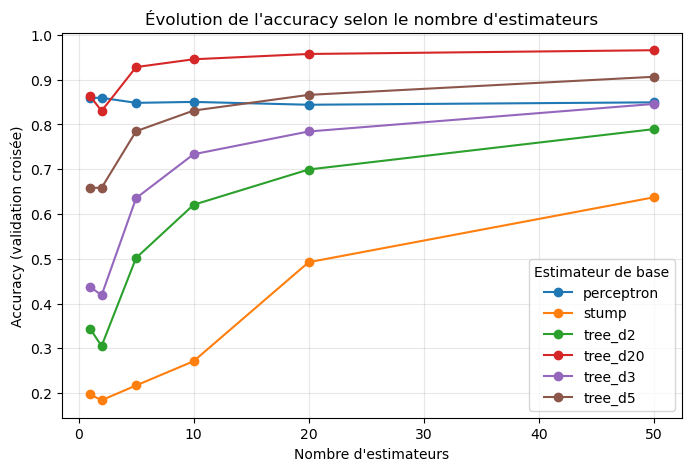

In [200]:
fig, ax = plt.subplots(figsize=(8, 5))

for estimator_name, sub in df_results.groupby("estimator"):
    ax.plot(sub["n_estimators"], sub["accuracy"],
            marker="o", label=estimator_name)
    ax.fill_between(sub["n_estimators"],
                    sub["accuracy"],
                    sub["accuracy"],
                    alpha=0.15)

ax.set_xlabel("Nombre d'estimateurs")
ax.set_ylabel("Accuracy (validation croisée)")
ax.set_title("Évolution de l'accuracy selon le nombre d'estimateurs")
ax.legend(title="Estimateur de base")
ax.grid(True, alpha=0.3)
plt.savefig("images/graphs/accuracy_vs_n_estimators.png", dpi=300, bbox_inches="tight")
plt.show()

<img src="images/graphs/accuracy_vs_n_estimators.png" alt= "Matrice de confusion perceptron" width="500">

- Pour les arbree, les meilleures performances sont obtenues avec un nombre d'estimateurs de 50. Pour le perceptron, le meilleur taux de bonne classification est obtenu avec 1 perceptron.
- Nous observons que pour les arbres, plus le nombre d'estimateurs augmente, plus le taux de bonne classification augmente. Nous constatons aussi que plus l'arbre à une profondeur maximale importante, plus le taux de bonne classification est important (pour un nombre d'estimateurs maximal de 50).
- Plus la profondeur maximale est importante moins le taux de bonne classification augmente avec le nombre d'estimateurs. \
\
L'augmentation du nombre d'estimateurs joue sans doute le rôle de nouvelles conditions qui vont affiner la classification. Cela explique que le taux de bonne classification augmente moins vite pour arbres avec une profondeur maximale plus importante, ceux-ci ont déjà de nombreuses règles de classification, en ajouter augmente moins la performance.

Pour le perceptron nous observons le phénomène inverse, le taux de bonne classification diminue légèrement lorsque l'on en rajoute.



#### Matrices de confusion

Nous observons ici les matrices de confusion pour chaque configuration.

<img src="images/cm_AdaBoost/cm_stump_all.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2_all.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3_all.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5_all.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20_all.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron_all.png" alt= "Matrice de confusion perceptron" width="500">

Comparaison des confusions lorsque l'on augmente le nombre de classifieurs faibles :
- Pour les arbres nous observons bien que pour un petit nombre de classifieurs faibles avec peu de profondeur, le modèle apprend à classifier en ajoutant des règles : il classe une partie des chiffres dans un premier temps 1 et 7 pour le stump, puis au fur et à mesure que l'on ajoute des estimateurs, il apprend à classer de mieux en mieux.
- Pour les arbres à plus grande profondeur, le nombre de règles apprises dès le début étant plus grand, ils savent déjà mieux classer avec un petit nombre d'estimateurs.
- A partir d'une profondeur maximale de 5, le nombre de règles apprises avec un seul arbre est suffisant pour classer majoritairement les chiffre dans la bonne classe.

Comparaison des confusions pour les nombres d'estimateurs ayant le meilleur taux de bonne classification (50 pour les arbres et 1 pour le perceptron) :
- Sans surprise, nous observons pour les arbres que plus la profondeur maximale augmente, moins il y a de confusions.
- Nous constatons aussi que les chiffres pour lesquels il y a le plus de confusion sont les 4, 5, 8 et 9 pour les arbres. Pour le perceptron ce sont les 5 et 7.
- Pour les arbres nous observons notamment que les 5 et 3 ainsi que les 4 et 9 sont particulièrement confondus, même pour le modèle qui montre la meilleure performance.
- Le perceptron montre un nombre important de confusions du 5 avec pratiquement l'ensemble des autres chiffres.

### C. Etude de classes binaires

Nous étudions ici des problèmes binaires :

9 contre 4, 5 contre 3 et 8 contre 3 : trois paires parmis les plus confondus.
Pour que les résultats soient comparables avec le cas multiclasse, nous gardons le même découpage train/test que précédemment : nous filtrons X_train et X_test au lieu de refaire un train_test_split (aucune image de test du multiclasse ne se retrouve ainsi dans un train binaire).

Pour chaque cas, nous faisons varier le classifieur faible et le nombre d'étapes de boosting.

Nous utilisons le f1 score comme metrics étant donnée que nous somme dans un cas binaire.

#### 1. 9 vs 4

Séléction des 9 et des 4. \
**La classe 1 correspond aux 9 et la classe 0 aux 4.**

In [201]:
mask_train_9v4 = (y_train == 9) | (y_train == 4)
mask_test_9v4  = (y_test  == 9) | (y_test  == 4)
X_9v4_train,  y_9v4_train  = X_train[mask_train_9v4], (y_train[mask_train_9v4] == 9).astype(int)
X_9v4_test, y_9v4_test = X_test[mask_test_9v4], (y_test[mask_test_9v4] == 9).astype(int)
print(np.unique_counts(y_9v4_train), np.unique_counts(y_9v4_test))

UniqueCountsResult(values=array([0, 1]), counts=array([5237, 5206])) UniqueCountsResult(values=array([0, 1]), counts=array([1587, 1752]))


In [202]:
from sklearn.metrics import f1_score

results_9v4 = []

for estimator_name, estimator in estimators.items():
    # Figure avec une matrice de confusion par valeur de n_estimators
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
    axes = np.ravel(axes)

    for ax, n_est in zip(axes, n_estimators_list):
        model = AdaBoostClassifier(estimator=estimator,
                                   n_estimators=n_est,
                                   random_state=seed)

        # Cross-val : une seule passe par configuration.
        # y_pred_cv contient, pour chaque individu, la prédiction du fold
        # où il était en validation (prédictions "out-of-fold").
        y_pred_cv = cross_val_predict(model, X_9v4_train, y_9v4_train,
                                      cv=skf, n_jobs=-1)
        f1_score_cv = f1_score(y_9v4_train, y_pred_cv)

        # Résultats de la cross-val dans le dataframe
        results_9v4.append({"estimator": estimator_name,
                        "n_estimators": n_est,
                        "f1_score": f1_score_cv})

        # Matrice de confusion à partir de ces mêmes prédictions CV
        cm = confusion_matrix(y_9v4_train, y_pred_cv)
        disp = ConfusionMatrixDisplay(cm)
        disp.plot(ax=ax, colorbar=False)
        ax.set_title(f"n_estimators = {n_est}\nf1 cv = {f1_score_cv:.3f}")
    print(results_9v4)

    fig.suptitle(f"AdaBoost — {estimator_name}", fontsize=16)
    fig.tight_layout()
    fig.savefig(f"images/cm_AdaBoost/cm_{estimator_name}_9v4.png",
                dpi=300, bbox_inches="tight")
    plt.close(fig)

df_results9v4 = pd.DataFrame(results_9v4)
print(df_results9v4)

[{'estimator': 'stump', 'n_estimators': 1, 'accuracy': 0.19706666666666667}, {'estimator': 'stump', 'n_estimators': 2, 'accuracy': 0.18420952380952382}, {'estimator': 'stump', 'n_estimators': 5, 'accuracy': 0.2172}, {'estimator': 'stump', 'n_estimators': 10, 'accuracy': 0.2713904761904762}, {'estimator': 'stump', 'n_estimators': 20, 'accuracy': 0.49241904761904765}, {'estimator': 'stump', 'n_estimators': 50, 'accuracy': 0.6373142857142857}, {'estimator': 'tree_d2', 'n_estimators': 1, 'accuracy': 0.34394285714285716}, {'estimator': 'tree_d2', 'n_estimators': 2, 'accuracy': 0.30525714285714284}, {'estimator': 'tree_d2', 'n_estimators': 5, 'accuracy': 0.5019619047619047}, {'estimator': 'tree_d2', 'n_estimators': 10, 'accuracy': 0.6207047619047619}, {'estimator': 'tree_d2', 'n_estimators': 20, 'accuracy': 0.6994666666666667}, {'estimator': 'tree_d2', 'n_estimators': 50, 'accuracy': 0.7896}, {'estimator': 'tree_d3', 'n_estimators': 1, 'accuracy': 0.4377333333333333}, {'estimator': 'tree_d3'

Construction d'un dataframe avec les resultats de la recherche. \
*Chemin : results/AdaBoost_cv_results_9v4.csv*

In [ ]:
df_results9v4.to_csv("results/AdaBoost_cv_results_9v4.csv", sep=";") # transformation en csv

<img src="images/cm_AdaBoost/cm_stump_9v4.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2_9v4.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3_9v4.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5_9v4.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20_9v4.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron_9v4.png" alt= "Matrice de confusion perceptron" width="500">

Pour la classification du 9 et du 4, le nombre de confusions est resté équilibré lors de nos testes, il n'y a pas un des deux chiffres qui est systématiquement moins bien reconnu.

Nous observons que les modèles dont l'estimateur est un arbre de profondeur 3, 5 ou 20 avec 50 estimateurs sont les plus performants (f1 ≈ 0,98, au mieux 0,986 avec la profondeur 5). La différence de performance entre ces trois configurations est très faible.

Un arbre de profondeur 20 seul atteint déjà un f1 de 0,955 : la profondeur importante permet d'avoir un nombre de règles suffisant pour bien distinguer les deux chiffres, et le boosting ne l'améliore que marginalement (0,985 à 50 estimateurs).

La performance des perceptrons n'augmente pas avec le nombre d'étapes (f1 ≈ 0,95 pour toutes les valeurs, légèrement meilleur à 5 estimateurs avec 0,958) : ajouter des perceptrons ne permet pas de mieux distinguer les classes. Le perceptron seul permet donc de trouver une séparatrice linéaire satisfaisante pour séparer le 9 et le 4.

#### 2. 5 vs 3

Séléction des 5 et des 3. \
**La classe 1 correspond aux 5 et la classe 0 aux 3.**

In [172]:
mask_train_5v3 = (y_train == 5) | (y_train == 3)
mask_test_5v3  = (y_test  == 5) | (y_test  == 3)
X_5v3_train, y_5v3_train  = X_train[mask_train_5v3], (y_train[mask_train_5v3] == 5).astype(int)
X_5v3_test, y_5v3_test = X_test[mask_test_5v3], (y_test[mask_test_5v3] == 5).astype(int)
print(np.unique_counts(y_5v3_train), np.unique_counts(y_5v3_test))

UniqueCountsResult(values=array([0, 1]), counts=array([5335, 4706])) UniqueCountsResult(values=array([0, 1]), counts=array([1806, 1607]))


In [203]:
from sklearn.metrics import f1_score

results_5v3 = []

for estimator_name, estimator in estimators.items():
    # Figure avec une matrice de confusion par valeur de n_estimators
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
    axes = np.ravel(axes)

    for ax, n_est in zip(axes, n_estimators_list):
        model = AdaBoostClassifier(estimator=estimator,
                                   n_estimators=n_est,
                                   random_state=seed)

        # Cross-val : une seule passe par configuration.
        # y_pred_cv contient, pour chaque individu, la prédiction du fold
        # où il était en validation (prédictions "out-of-fold").
        y_pred_cv = cross_val_predict(model, X_5v3_train, y_5v3_train,
                                      cv=skf, n_jobs=-1)
        f1_score_cv = f1_score(y_5v3_train, y_pred_cv)

        # Résultats de la cross-val dans le dataframe
        results_5v3.append({"estimator": estimator_name,
                        "n_estimators": n_est,
                        "f1_score": f1_score_cv})

        # Matrice de confusion à partir de ces mêmes prédictions CV
        cm = confusion_matrix(y_5v3_train, y_pred_cv)
        disp = ConfusionMatrixDisplay(cm)
        disp.plot(ax=ax, colorbar=False)
        ax.set_title(f"n_estimators = {n_est}\nf1 cv = {f1_score_cv:.3f}")
    print(results_5v3)

    fig.suptitle(f"AdaBoost — {estimator_name}", fontsize=16)
    fig.tight_layout()
    fig.savefig(f"images/cm_AdaBoost/cm_{estimator_name}_5v3.png",
                dpi=300, bbox_inches="tight")
    plt.close(fig)

df_results5v3 = pd.DataFrame(results_5v3)
print(df_results5v3)

[{'estimator': 'stump', 'n_estimators': 1, 'f1_score': 0.7138134592680048}, {'estimator': 'stump', 'n_estimators': 2, 'f1_score': 0.7138134592680048}, {'estimator': 'stump', 'n_estimators': 5, 'f1_score': 0.8016260162601626}, {'estimator': 'stump', 'n_estimators': 10, 'f1_score': 0.8375410392845013}, {'estimator': 'stump', 'n_estimators': 20, 'f1_score': 0.8813782508504334}, {'estimator': 'stump', 'n_estimators': 50, 'f1_score': 0.9286778794975517}]
[{'estimator': 'stump', 'n_estimators': 1, 'f1_score': 0.7138134592680048}, {'estimator': 'stump', 'n_estimators': 2, 'f1_score': 0.7138134592680048}, {'estimator': 'stump', 'n_estimators': 5, 'f1_score': 0.8016260162601626}, {'estimator': 'stump', 'n_estimators': 10, 'f1_score': 0.8375410392845013}, {'estimator': 'stump', 'n_estimators': 20, 'f1_score': 0.8813782508504334}, {'estimator': 'stump', 'n_estimators': 50, 'f1_score': 0.9286778794975517}, {'estimator': 'tree_d2', 'n_estimators': 1, 'f1_score': 0.7918314979151074}, {'estimator': '

Construction d'un dataframe avec les resultats de la recherche. \
*Chemin : results/AdaBoost_cv_results_5v3.csv*

In [ ]:
df_results5v3.to_csv("results/AdaBoost_cv_results_5v3.csv", sep=";") # transformation en csv

<img src="images/cm_AdaBoost/cm_stump_5v3.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2_5v3.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3_5v3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5_5v3.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20_5v3.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron_5v3.png" alt= "Matrice de confusion perceptron" width="500">

La paire 5 vs 3 est la plus difficile des trois paires binaires : avec un seul classifieur faible, le f1 est de 0,71 pour le stump, contre 0,87 pour 9 vs 4 et 0,85 pour 8 vs 3. C'est cohérent avec la forme des chiffres : 5 et 3 partagent la même boucle inférieure, aucun pixel unique ne les sépare.

Le boosting permet de surmonter cette difficulté : le f1 du stump passe de 0,71 à 0,93 entre 1 et 50 étapes (+22 points, la plus forte progression des trois paires). Les erreurs étant réparties sur plusieurs zones de l'image, chaque nouveau stump affine une zone différente.

La meilleure configuration est l'arbre de profondeur 5 avec 50 estimateurs (f1 = 0,99), devant les profondeurs 3 et 20 (0,98). Le problème étant simple (deux classes), la profondeur 5 offre le meilleur compromis biais-variance : les arbres de profondeur 20, déjà très performants seuls (0,95 avec un seul arbre), progressent moins au fil des étapes.

On remarque aussi que pour la plupart des estimateurs, passer de 1 à 2 estimateurs ne change pas le score : le deuxième classifieur, entraîné sur les mêmes exemples difficiles, n'apporte pas de règle véritablement nouvelle.

Enfin, le perceptron est le seul estimateur dont le f1 ne progresse pas avec le nombre d'étapes (≈ 0,94 à 0,95 pour toutes les valeurs). Comme on le constatera pour les autres paires, le boosting n'améliore pas un classifieur déjà presque optimal.

#### 3. 8 vs 3

Séléction des 8 et des 3. \
**La classe 1 correspond aux 8 et la classe 0 aux 3.**

In [207]:
mask_train_8v3 = (y_train == 8) | (y_train == 3)
mask_test_8v3  = (y_test  == 8) | (y_test  == 3)
X_8v3_train,  y_8v3_train  = X_train[mask_train_8v3], (y_train[mask_train_8v3] == 8).astype(int)
X_8v3_test, y_8v3_test = X_test[mask_test_8v3], (y_test[mask_test_8v3] == 8).astype(int)
print(np.unique_counts(y_8v3_train), np.unique_counts(y_8v3_test))

UniqueCountsResult(values=array([0, 1]), counts=array([5335, 5168])) UniqueCountsResult(values=array([0, 1]), counts=array([1806, 1657]))


In [208]:
results_8v3 = []

for estimator_name, estimator in estimators.items():
    # Figure avec une matrice de confusion par valeur de n_estimators
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
    axes = np.ravel(axes)

    for ax, n_est in zip(axes, n_estimators_list):
        model = AdaBoostClassifier(estimator=estimator,
                                   n_estimators=n_est,
                                   random_state=seed)

        # Cross-val : une seule passe par configuration.
        # y_pred_cv contient, pour chaque individu, la prédiction du fold
        # où il était en validation (prédictions "out-of-fold").
        y_pred_cv = cross_val_predict(model, X_8v3_train, y_8v3_train,
                                      cv=skf, n_jobs=-1)
        f1_score_cv = f1_score(y_8v3_train, y_pred_cv)

        # Résultats de la cross-val dans le dataframe
        results_8v3.append({"estimator": estimator_name,
                        "n_estimators": n_est,
                        "f1_score": f1_score_cv})

        # Matrice de confusion à partir de ces mêmes prédictions CV
        cm = confusion_matrix(y_8v3_train, y_pred_cv)
        disp = ConfusionMatrixDisplay(cm)
        disp.plot(ax=ax, colorbar=False)
        ax.set_title(f"n_estimators = {n_est}\nf1 cv = {f1_score_cv:.3f}")
    print(results_8v3)

    fig.suptitle(f"AdaBoost — {estimator_name}", fontsize=16)
    fig.tight_layout()
    fig.savefig(f"images/cm_AdaBoost/cm_{estimator_name}_8v3.png",
                dpi=300, bbox_inches="tight")
    plt.close(fig)

df_results8v3 = pd.DataFrame(results_8v3)
print(df_results8v3)

[{'estimator': 'stump', 'n_estimators': 1, 'f1_score': 0.8547224926971763}, {'estimator': 'stump', 'n_estimators': 2, 'f1_score': 0.8547224926971763}, {'estimator': 'stump', 'n_estimators': 5, 'f1_score': 0.8782642843118005}, {'estimator': 'stump', 'n_estimators': 10, 'f1_score': 0.9084115730982947}, {'estimator': 'stump', 'n_estimators': 20, 'f1_score': 0.9224062772449869}, {'estimator': 'stump', 'n_estimators': 50, 'f1_score': 0.9459303444294785}]
[{'estimator': 'stump', 'n_estimators': 1, 'f1_score': 0.8547224926971763}, {'estimator': 'stump', 'n_estimators': 2, 'f1_score': 0.8547224926971763}, {'estimator': 'stump', 'n_estimators': 5, 'f1_score': 0.8782642843118005}, {'estimator': 'stump', 'n_estimators': 10, 'f1_score': 0.9084115730982947}, {'estimator': 'stump', 'n_estimators': 20, 'f1_score': 0.9224062772449869}, {'estimator': 'stump', 'n_estimators': 50, 'f1_score': 0.9459303444294785}, {'estimator': 'tree_d2', 'n_estimators': 1, 'f1_score': 0.8953729933899905}, {'estimator': '

Construction d'un dataframe avec les resultats de la recherche. \
*Chemin : results/AdaBoost_cv_results_8v3.csv*

In [209]:
df_results8v3.to_csv("results/AdaBoost_cv_results_8v3.csv", sep=";") # transformation en csv

<img src="images/cm_AdaBoost/cm_stump_8v3.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2_8v3.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3_8v3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5_8v3.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20_8v3.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron_8v3.png" alt= "Matrice de confusion perceptron" width="500">

8 vs 3 se comporte comme les deux autres paires : le f1 croît avec le nombre d'étapes pour tous les arbres, et la meilleure configuration est encore l'arbre de profondeur 5 avec 50 estimateurs (f1 = 0,991), le meilleur score des trois problèmes binaires.

Deux points méritent d'être soulignés :

le perceptron a ici une performance identique à l'arbre de profondeur 20 dès le départ (0,957 avec un seul estimateur, 0,953 avec 50) : 8 et 3 étant des formes globalement différentes, une frontière linéaire les sépare presque entièrement, et le boosting n'apporte presque plus rien (l'arbre de profondeur 20 passe de 0,957 à 0,987 avec 50 estimateurs) ;

c'est le seul cas où ajouter un estimateur dégrade légèrement la performance : l'arbre de profondeur 20 passe de 0,957 (1 estimateur) à 0,950 (2 estimateurs). Le premier arbre étant déjà quasi optimal, le second, entraîné sur les quelques exemples difficiles restants, apprend surtout du bruit et perturbe légèrement la pondération.

Les matrices de confusion confirment que les erreurs résiduelles sont rares et portent sur des écritures ambiguës, par exemple des 3 dont la boucle n'est pas fermée, proches d'un 8.

#### 4. 0-4 vs 5-9

Séléction des groupes de chiffre de 0 à 4 et de 5 à 9. \
**La classe 1 correspond au groupe 0 à 4 et la classe 0 au groupe 5 à 9.**

In [227]:
X_04v59_train, y_04v59_train = X_train, (y_train <= 4).astype(int)
X_04v59_test,  y_04v59_test  = X_test,  (y_test  <= 4).astype(int)
print(np.unique_counts(y_04v59_train), np.unique_counts(y_04v59_test))

UniqueCountsResult(values=array([0, 1]), counts=array([25610, 26890])) UniqueCountsResult(values=array([0, 1]), counts=array([8655, 8845]))


In [ ]:
results_04v59 = []

for estimator_name, estimator in estimators.items():
    # Figure avec une matrice de confusion par valeur de n_estimators
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(5 * n_cols, 4.5 * n_rows))
    axes = np.ravel(axes)

    for ax, n_est in zip(axes, n_estimators_list):
        model = AdaBoostClassifier(estimator=estimator,
                                   n_estimators=n_est,
                                   random_state=seed)

        # Cross-val : une seule passe par configuration.
        # y_pred_cv contient, pour chaque individu, la prédiction du fold
        # où il était en validation (prédictions "out-of-fold").
        y_pred_cv = cross_val_predict(model, X_04v59_train, y_04v59_train,
                                      cv=skf, n_jobs=-1)
        f1_score_cv = f1_score(y_04v59_train, y_pred_cv)

        # Résultats de la cross-val dans le dataframe
        results_04v59.append({"estimator": estimator_name,
                        "n_estimators": n_est,
                        "f1_score": f1_score_cv})

        # Matrice de confusion à partir de ces mêmes prédictions CV
        cm = confusion_matrix(y_04v59_train, y_pred_cv)
        disp = ConfusionMatrixDisplay(cm)
        disp.plot(ax=ax, colorbar=False)
        ax.set_title(f"n_estimators = {n_est}\nf1 cv = {f1_score_cv:.3f}")
    print(results_04v59)

    fig.suptitle(f"AdaBoost — {estimator_name}", fontsize=16)
    fig.tight_layout()
    fig.savefig(f"images/cm_AdaBoost/cm_{estimator_name}_04v59.png",
                dpi=300, bbox_inches="tight")
    plt.close(fig)

df_results_04v59 = pd.DataFrame(results_04v59)
print(df_results_04v59)

[{'estimator': 'stump', 'n_estimators': 1, 'f1_score': 0.6502936241610738}, {'estimator': 'stump', 'n_estimators': 2, 'f1_score': 0.6502936241610738}, {'estimator': 'stump', 'n_estimators': 5, 'f1_score': 0.7553093259464451}, {'estimator': 'stump', 'n_estimators': 10, 'f1_score': 0.7590072057646117}, {'estimator': 'stump', 'n_estimators': 20, 'f1_score': 0.797344293392349}, {'estimator': 'stump', 'n_estimators': 50, 'f1_score': 0.8097071129707113}]
[{'estimator': 'stump', 'n_estimators': 1, 'f1_score': 0.6502936241610738}, {'estimator': 'stump', 'n_estimators': 2, 'f1_score': 0.6502936241610738}, {'estimator': 'stump', 'n_estimators': 5, 'f1_score': 0.7553093259464451}, {'estimator': 'stump', 'n_estimators': 10, 'f1_score': 0.7590072057646117}, {'estimator': 'stump', 'n_estimators': 20, 'f1_score': 0.797344293392349}, {'estimator': 'stump', 'n_estimators': 50, 'f1_score': 0.8097071129707113}, {'estimator': 'tree_d2', 'n_estimators': 1, 'f1_score': 0.7465451337841811}, {'estimator': 'tr

Construction d'un dataframe avec les resultats de la recherche. \
*Chemin : results/AdaBoost_cv_results_8v3.csv*

In [ ]:
df_results_04v59.to_csv("results/AdaBoost_cv_results_04v59.csv", sep=";") # transformation en csv

<img src="images/cm_AdaBoost/cm_stump_04v59.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_tree_d2_04v59.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_tree_d3_04v59.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_tree_d5_04v59.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_tree_d20_04v59.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_perceptron_04v59.png" alt= "Matrice de confusion perceptron" width="500">

### D. Bilan

**Multiclasse :** À 50 étapes de boosting, l'accuracy croît avec la complexité du classifieur faible : stump 0,64 ; arbre de profondeur 2 : 0,79 ; profondeur 3 : 0,85 ; profondeur 5 : 0,91 ; profondeur 20 : 0,97 ; le perceptron (0,86) se place entre les profondeurs 3 et 5. Le stump est très défavorable en multiclasse : une seule règle par étape ne peut séparer qu'un groupe de chiffres d'un autre, et à 50 étapes le score continue de grimper nettement (0,49 → 0,64 entre 20 et 50 étapes).

**Nombre d'étapes :** Pour tous les arbres, le meilleur n_estimators vaut toujours 50, la borne haute de la grille : aucune courbe n'a atteint son plateau, la croissance reste marquée entre 20 et 50 étapes, et il faudrait prolonger la grille (100, 200 étapes) pour situer le palier. Seul le perceptron fait exception : son meilleur score est atteint dès 1 estimateur (0,86) puis stagne et diminue légèrement (0,85 à 50). Le boosting n'apporte rien à un classifieur déjà performant : il est conçu pour combiner des apprenants faibles.

**Binaire vs multiclasse :** En binaire, le stump redevient nettement compétitif : f1 de 0,93 (5 vs 3) à 0,94 (9 vs 4 et 8 vs 3) à 50 étapes, contre 0,64 seulement en multiclasse. C'est assez logique : une règle binaire par étape suffit à séparer deux classes, alors qu'il en faut beaucoup pour en séparer dix. On note aussi une inversion par rapport au multiclasse : en binaire, la profondeur 5 bat la profondeur 20 (0,99 contre 0,98). Sur un problème simple, les arbres trop profonds n'ont plus d'utilité pour leur capacité, tandis qu'en multiclasse cette même capacité leur donne le meilleur score.

**Paire la plus difficile :** 5 vs 3 : c'est la paire qui fait l'objet du plus de confusions avec des classifieurs faibles (f1 de 0,71 pour un stump, contre 0,87 pour 9 vs 4 et 0,85 pour 8 vs 3), ce qui est cohérent avec les confusions 5/3 observées dès la première modélisation (partie A). Mais à 50 étapes, les trois paires convergent toutes vers f1 ≈ 0,99, y compris avec des stumps : ces problèmes binaires sont faciles pour AdaBoost.

**Configurations les plus favorables et défavorables :** La plus favorable reste le regroupement 50 estimateurs × arbres de profondeur 20 en multiclasse (0,97 en validation croisée), sous réserve que la borne haute de la grille n'ait pas encore révélé le plateau. La plus défavorable est le stump unique en multiclasse (0,20) : une seule règle pour dix classes.

## 2. Réalisation de cartes de saillance

#### Entre deux chiffres

In [212]:
def carte_saillance(model):
    saillance = np.zeros(784)                      # un compteur par pixel, tous à 0
    for stump, alpha in zip(model.estimators_, model.estimator_weights_):
        pixel = stump.tree_.feature[0]             # pixel testé par ce stump
        if pixel >= 0:                             # sécurité : -2 veut dire « pas de test »
            saillance[pixel] += alpha              # on ajoute le poids du stump à ce pixel
    return saillance.reshape(28, 28)               # 784 valeurs -> image 28x28

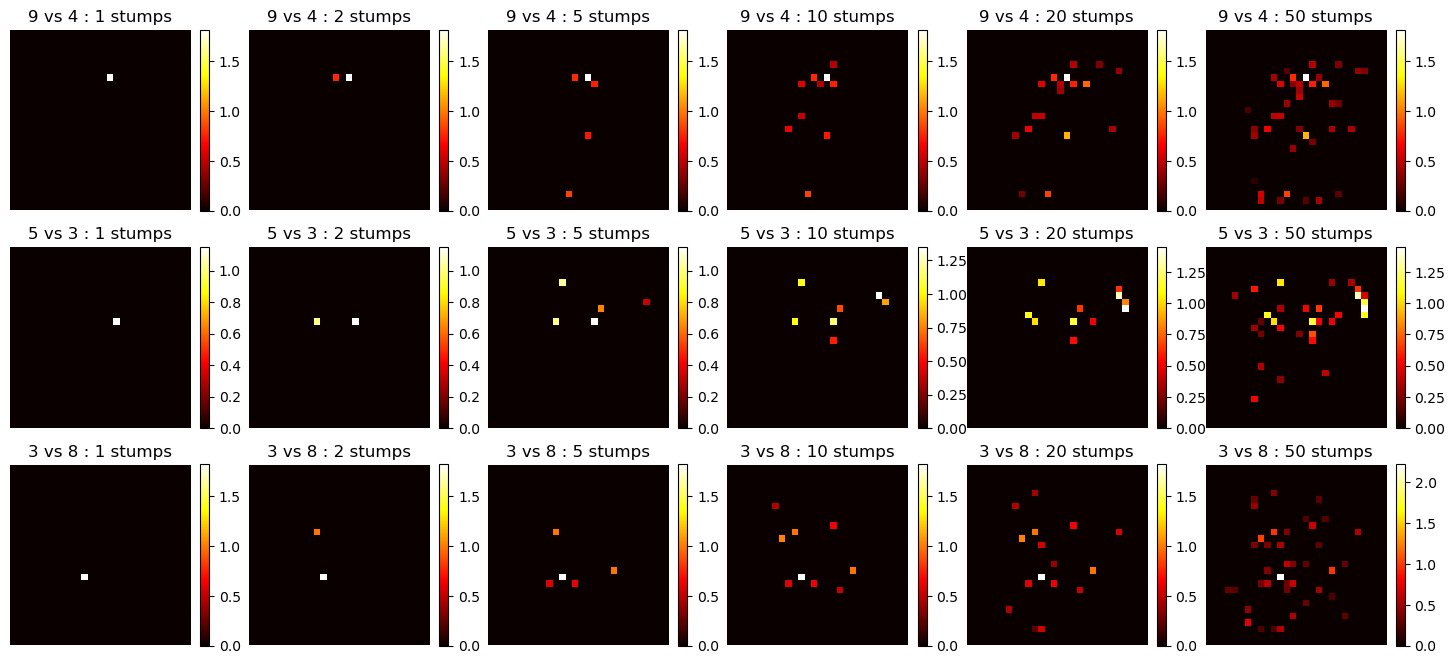

In [215]:
cas = {"9 vs 4": (X_9v4_train, y_9v4_train),
       "5 vs 3": (X_5v3_train, y_5v3_train),
       "3 vs 8": (X_8v3_train, y_8v3_train)}
etapes = [1, 2, 5, 10, 20, 50]

fig, axes = plt.subplots(3, 6, figsize=(18, 8))

for i, (nom, (X_tr, y_tr)) in enumerate(cas.items()):
    for j, n in enumerate(etapes):
        model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                   n_estimators=n, random_state=42)
        model.fit(X_tr, y_tr)

        im = axes[i, j].imshow(carte_saillance(model), cmap="hot")
        axes[i, j].set_title(f"{nom} : {n} stumps")
        axes[i, j].axis("off")
        fig.colorbar(im, ax=axes[i, j], fraction=0.046)

plt.savefig("images/saillance_map/saillance_binaires.png", dpi=300, bbox_inches="tight")

<img src="images/saillance_map/saillance_binaires.png" alt= "Matrice de confusion décision stump" width="1200">

#### Cartes de saillance entre groupes de chiffre (0-4 puis 5-9)

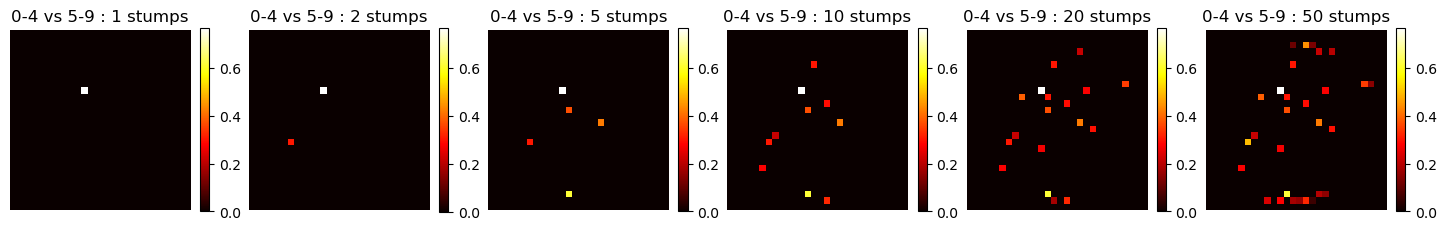

In [220]:
def preparer(chiffres_1, chiffres_0):
    mask = np.isin(y, chiffres_1 + chiffres_0)                       # garde seulement ces chiffres
    X_b, y_b = X[mask], np.isin(y[mask], chiffres_1).astype(int)     # 1 = premier groupe, 0 = second
    X_tr, X_te, y_tr, y_te = train_test_split(X_b, y_b, test_size=0.25, random_state=42)
    return X_tr, y_tr

cas = {"0-4 vs 5-9": preparer([0, 1, 2, 3, 4], [5, 6, 7, 8, 9])}
etapes = [1, 2, 5, 10, 20, 50]

fig, axes = plt.subplots(1, 6, figsize=(18, 8))
axes = np.atleast_2d(axes)
for i, (nom, (X_tr, y_tr)) in enumerate(cas.items()):
    for j, n in enumerate(etapes):
        model = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                   n_estimators=n, random_state=42)
        model.fit(X_tr, y_tr)

        im = axes[i, j].imshow(carte_saillance(model), cmap="hot")
        axes[i, j].set_title(f"{nom} : {n} stumps")
        axes[i, j].axis("off")
        fig.colorbar(im, ax=axes[i, j], fraction=0.046)

plt.savefig("images/saillance_map/saillance_binaires_0-4v5-9.png", dpi=300, bbox_inches="tight")

<img src="images/saillance_map/saillance_binaires_0-4v5-9.png" alt= "Matrice de confusion décision stump" width="1000">

### Conclusion : On a tracé deux types de carte de saillance, binaires (5vs3 et 9vs4) puis de groupe (0-4 vs 5-9).

##### On a une carte directement lisible car un stump = un pixel. La carte indique quels pixels le modèle utilise, et à quel point il s’appuie dessus.
##### On remarque que peu de pixels suffisent pour une paire de chiffres. Dès 5 stumps, quelques pixels ressortent nettement, et un pixel domine souvent (en haut au centre pour 9 vs 4, vers le centre pour 3 vs 8).
##### On voit également que les pixels dominants sont stables quand le nombre d’étapes augmente. Effectivement, passer de 5 à 100 étapes ajoute des pixels autour, sans déplacer les principaux de base.
##### Avec plus d’étapes on obtient une carte plus étendue et plus diffuse. Les stumps ajoutés tardivement ont un faible poids et apportent surtout de petits ajustements.

##### Surtout, on voit que les groupes de chiffres donnent des cartes beaucoup moins interprétables. Pour 0–4 vs 5–9, on voit que les pixels sont éparpillés, sans zone qui domine et le poids maximal est bien plus bas. Un 0 et un 1 n’ont presque rien en commun, alors qu’ils sont dans la même classe : aucun pixel ne sépare bien les deux groupes.

## 3. Embedding

Elaboration d'un ensemble de test réduit pour raccourcir les temps de calculs.

In [139]:
N_TRAIN = 8000           # taille du sous-échantillon train
N_TEST = int(0.25 * N_TRAIN)  # taille du sous-échantillon test

rng = np.random.default_rng(seed)
idx_tr = rng.choice(len(X_train), N_TRAIN, replace=False)
idx_te = rng.choice(len(X_test), N_TEST, replace=False)
X_train_FR, y_train_FR = X_train[idx_tr], y_train[idx_tr]
X_test_FR, y_test_FR = X_test[idx_te], y_test[idx_te]

#### 1. Entrainement d'un MLP

Apprentissage d'un perceptron multicouche à 1 couche cachée.

In [156]:
from sklearn.neural_network import MLPRegressor

n_hidden = 64

mlp = MLPRegressor(
    hidden_layer_sizes=(n_hidden,),
    activation="relu",          # fonction d'activagion cachée = relu
    solver="adam",
    max_iter=1000,
    early_stopping=True,        # coupe sur la MSE de reconstruction
    n_iter_no_change=10,
    random_state=seed,
    verbose=True,
        )
mlp.fit(X_train, X_train)


Iteration 1, loss = 0.02050576
Validation score: -3.179788
Iteration 2, loss = 0.00852125
Validation score: -0.433602
Iteration 3, loss = 0.00675058
Validation score: 0.257337
Iteration 4, loss = 0.00609240
Validation score: 0.364428
Iteration 5, loss = 0.00587937
Validation score: 0.363031
Iteration 6, loss = 0.00574199
Validation score: 0.344606
Iteration 7, loss = 0.00556030
Validation score: 0.349673
Iteration 8, loss = 0.00546578
Validation score: 0.372870
Iteration 9, loss = 0.00540825
Validation score: 0.301769
Iteration 10, loss = 0.00527833
Validation score: 0.400884
Iteration 11, loss = 0.00508960
Validation score: 0.408388
Iteration 12, loss = 0.00502375
Validation score: 0.344756
Iteration 13, loss = 0.00500505
Validation score: 0.382483
Iteration 14, loss = 0.00490276
Validation score: 0.410030
Iteration 15, loss = 0.00484999
Validation score: 0.394747
Iteration 16, loss = 0.00483970
Validation score: 0.393439
Iteration 17, loss = 0.00482847
Validation score: 0.428575
Iter

,loss,'squared_error'
,hidden_layer_sizes,"(64,)"
,activation,'relu'
,solver,'adam'
,alpha,0.0001
,batch_size,'auto'
,learning_rate,'constant'
,learning_rate_init,0.001
,power_t,0.5
,max_iter,1000
,shuffle,True


On réalise une fonction d'embedding.

In [157]:
def embed(mlp, X):
    """Activités de la couche cachée = description dans l'espace de
    redescription. Identique à h = relu(X @ W1 + b1)."""
    Z = X @ mlp.coefs_[0] + mlp.intercepts_[0]
    return np.maximum(Z, 0.0)

On crée une fonction de reconstruction vers l'espace original.

In [158]:
def reconstruct(mlp, X):
    """Sortie du réseau complet (reconstruction 784 pixels)."""
    return embed(mlp, X) @ mlp.coefs_[1] + mlp.intercepts_[1]

Visualisation des images.

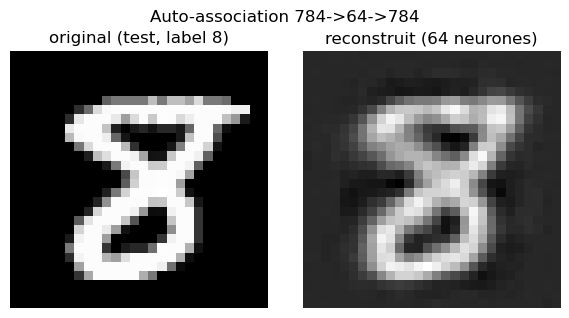

In [159]:
#autoenc = mlp.predict(X_test_FR)
#recon = reconstruct(autoenc, X_test_FR)

img_idx = 0                     # image de test choisie
img = X_test[img_idx]
#img_rec = reconstruct(autoenc, img[None, :]).reshape(28, 28)
img_rec = mlp.predict(img[None, :]).reshape(28, 28)

fig, axes = plt.subplots(1, 2, figsize=(6, 3.2))
axes[0].imshow(img.reshape(28, 28), cmap="gray")
axes[0].set_title(f"original (test, label {y_test[img_idx]})")
axes[1].imshow(img_rec, cmap="gray")
axes[1].set_title(f"reconstruit ({n_hidden} neurones)")
for ax in axes:
    ax.axis("off")
fig.suptitle(f"Auto-association 784->{n_hidden}->784")
fig.tight_layout()
plt.savefig("images/image1_autoencodage.png", dpi=300, bbox_inches="tight")
#plt.close(fig)


#### 2. AdaBoost sur l'embedding

Création des datasets embed

In [145]:
E_train_FR = embed(mlp, X_train_FR)
E_test_FR = embed(mlp, X_test_FR)
print(f"Embedding train: {E_train_FR.shape}, test: {E_test_FR.shape}")

Embedding train: (8000, 64), test: (2000, 64)


In [160]:
E_train = embed(mlp, X_train)
E_test = embed(mlp, X_test)
print(f"Embedding train: {E_train.shape}, test: {E_test.shape}")

Embedding train: (52500, 64), test: (17500, 64)


Paramètres à tester

In [161]:
from sklearn.linear_model import Perceptron

estimators = {"stump": DecisionTreeClassifier(max_depth=1),
              "tree_d2": DecisionTreeClassifier(max_depth=2),
              "tree_d5": DecisionTreeClassifier(max_depth=5),
              "tree_d20": DecisionTreeClassifier(max_depth=20),
              "perceptron": Perceptron(max_iter=1000, tol=1e-3, random_state=seed)}

params = {"n_estimators" : [1, 2, 5, 10, 20, 50]}

Gridsearch sur l'embedding.

In [162]:
from sklearn.model_selection import GridSearchCV

results_embed = []
best_results_embed = []

for estimator_name, estimator in estimators.items():
    ada_boost = AdaBoostClassifier(estimator=estimator, random_state=seed)

    grid = GridSearchCV(estimator=ada_boost, param_grid=params, scoring="accuracy", cv=skf, n_jobs=-1)

    grid.fit(E_train, y_train)
    acc = grid.best_score_
    best = grid.best_estimator_

    # Resultats des cross val
    best_results_embed.append({"estimator" : estimator_name, "accuracy" : acc, "n_estimators" : grid.best_params_["n_estimators"]}) # Meilleurs résultats
    print(best_results_embed)

    df_cv = pd.DataFrame(grid.cv_results_) # Ensemble des résultats
    df_cv["estimator"] = estimator_name
    results_embed.append(df_cv)

    # Matrice de confusion sur le test
    n_estimators = grid.best_params_["n_estimators"]
    y_pred = best.predict(E_test)
    acc_test = accuracy_score(y_test, y_pred)
    cm = confusion_matrix(y_test, y_pred)
    disp_cm = ConfusionMatrixDisplay(cm)
    disp_cm.plot()
    disp_cm.ax_.set_title(f"{n_estimators} X {estimator_name}. Accuracy = {acc_test}.")
    plt.savefig(f"images/cm_AdaBoost/cm_embedding_{estimator_name}.png", dpi=300, bbox_inches="tight")
    plt.close()

[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7007619047619047), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7007619047619047), 'n_estimators': 50}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.8299047619047618), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}, {'estimator': 'tree_d2', 'accuracy': np.float64(0.7007619047619047), 'n_estimators': 50}, {'estimator': 'tree_d5', 'accuracy': np.float64(0.8299047619047618), 'n_estimators': 50}, {'estimator': 'tree_d20', 'accuracy': np.float64(0.9416952380952381), 'n_estimators': 50}]
[{'estimator': 'stump', 'accuracy': np.float64(0.5840571428571428), 'n_estimators': 50}, {'estimator': 

<img src="images/cm_AdaBoost/cm_embedding_stump.png" alt= "Matrice de confusion décision stump" width="500">

<img src="images/cm_AdaBoost/cm_embedding_tree_d2.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

<img src="images/cm_AdaBoost/cm_embedding_tree_d3.png" alt= "Matrice de confusion arbre de profondeur 3" width="500">

<img src="images/cm_AdaBoost/cm_embedding_tree_d5.png" alt= "Matrice de confusion arbre de profondeur 5" width="500">

<img src="images/cm_AdaBoost/cm_embedding_tree_d20.png" alt= "Matrice de confusion arbre de profondeur 20" width="500">

<img src="images/cm_AdaBoost/cm_embedding_perceptron.png" alt= "Matrice de confusion perceptron" width="500">

In [163]:
df_cv_all_embed = pd.concat(results_embed, ignore_index=True)
df_accuracy_embed = (df_cv_all_embed.rename(columns={"param_n_estimators": "n_estimators", "mean_test_score": "accuracy_cv", "std_test_score": "std_cv"})[["estimator", "n_estimators", "accuracy_cv", "std_cv"]].sort_values(["estimator", "n_estimators"]).reset_index(drop=True))
df_accuracy_embed.to_csv("results/AdaBoost_cv_results_embed.csv", sep=";") # transformation en csv
df_accuracy_embed

,estimator,n_estimators,accuracy_cv,std_cv
0,perceptron,1,0.841924,0.024005
1,perceptron,2,0.841924,0.024005
2,perceptron,5,0.839162,0.014330
3,perceptron,10,0.853619,0.008061
4,perceptron,20,0.842171,0.005947
5,perceptron,50,0.840629,0.007473
6,stump,1,0.179010,0.001349
7,stump,2,0.170762,0.003306
8,stump,5,0.210248,0.020672
9,stump,10,0.323410,0.018405


In [165]:
df_best_results_embed = pd.DataFrame(best_results_embed, columns=["estimator", "accuracy", "n_estimators"])
df_best_results_embed.to_csv("results/AdaBoost_cv_best_results_embed.csv", sep=";") # transformation en csv
df_best_results_embed

,estimator,accuracy,n_estimators
0,stump,0.584057,50
1,tree_d2,0.700762,50
2,tree_d5,0.829905,50
3,tree_d20,0.941695,50
4,perceptron,0.853619,10


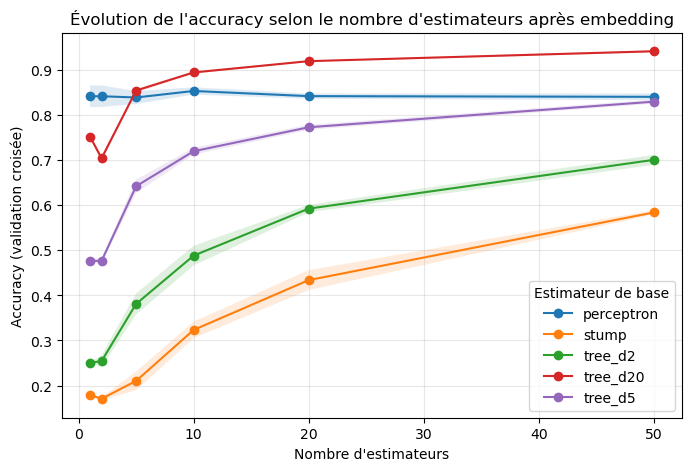

In [166]:
fig, ax = plt.subplots(figsize=(8, 5))

for estimator_name, sub in df_accuracy_embed.groupby("estimator"):
    ax.plot(sub["n_estimators"], sub["accuracy_cv"],
            marker="o", label=estimator_name)
    ax.fill_between(sub["n_estimators"],
                    sub["accuracy_cv"] - sub["std_cv"],
                    sub["accuracy_cv"] + sub["std_cv"],
                    alpha=0.15)

ax.set_xlabel("Nombre d'estimateurs")
ax.set_ylabel("Accuracy (validation croisée)")
ax.set_title("Évolution de l'accuracy selon le nombre d'estimateurs après embedding")
ax.legend(title="Estimateur de base")
ax.grid(True, alpha=0.3)
plt.savefig("images/graphs/accuracy_vs_n_estimators_embed.png", dpi=300, bbox_inches="tight")
plt.show()

<img src="images/graphs/accuracy_vs_n_estimators_embed.png" alt= "Matrice de confusion arbre de profondeur 2" width="500">

### 3. Saliency map

In [221]:
def lire_stump(stump):
    """Un stump teste UNE variable (un pixel ou un neurone) avec un seuil.
    On renvoie : (indice de la variable, signe).
      signe = +1 : le stump vote « classe + » quand la variable est GRANDE
      signe = -1 : le stump vote « classe + » quand la variable est PETITE
    """
    arbre = stump.tree_
    variable = arbre.feature[0]
    feuille_droite = arbre.children_right[0]
    classe_droite = np.argmax(arbre.value[feuille_droite])
    signe = 1 if classe_droite == 1 else -1
    return variable, signe

In [222]:
def poids_signes(model, T, n_variables):
    """w[j] = somme des poids alpha (avec signe) des T premiers stumps qui testent la variable j.
    w[j] > 0 : variable j grande -> le modèle penche vers la classe +
    w[j] < 0 : variable j grande -> le modèle penche vers la classe -
    """
    w = np.zeros(n_variables)
    for stump, alpha in zip(model.estimators_[:T], model.estimator_weights_[:T]):
        j, signe = lire_stump(stump)
        if j >= 0:
            w[j] += signe * alpha
    return w

W1 = mlp.coefs_[0]

In [223]:
def carte_pixels(model, T):
    """Stumps appris SUR LES PIXELS : un stump = un pixel, donc w est déjà une image 28x28."""
    return poids_signes(model, T, 784).reshape(28, 28)

In [224]:
def carte_embedding(model, T, E_paire):
    """Stumps appris SUR L'EMBEDDING : un stump = un neurone caché.
    On « rétropropage » jusqu'aux pixels (idée de GradCAM) :
        score(x) = somme_j w[j] * h_j(x)   avec   h_j = relu(x @ W1[:, j] + b1[j])
        d score / d pixel_p = somme_j w[j] * porte_j * W1[p, j]
    où porte_j = 1 si le neurone j est actif (relu non nulle), 0 sinon.
    On prend la moyenne de porte_j sur les images de la paire (pour avoir une seule carte par paire).
    """
    w = poids_signes(model, T, W1.shape[1])
    porte = (E_paire > 0).mean(axis=0)
    return (W1 @ (w * porte)).reshape(28, 28)

On affiche une carte

La classe + sera en rouge

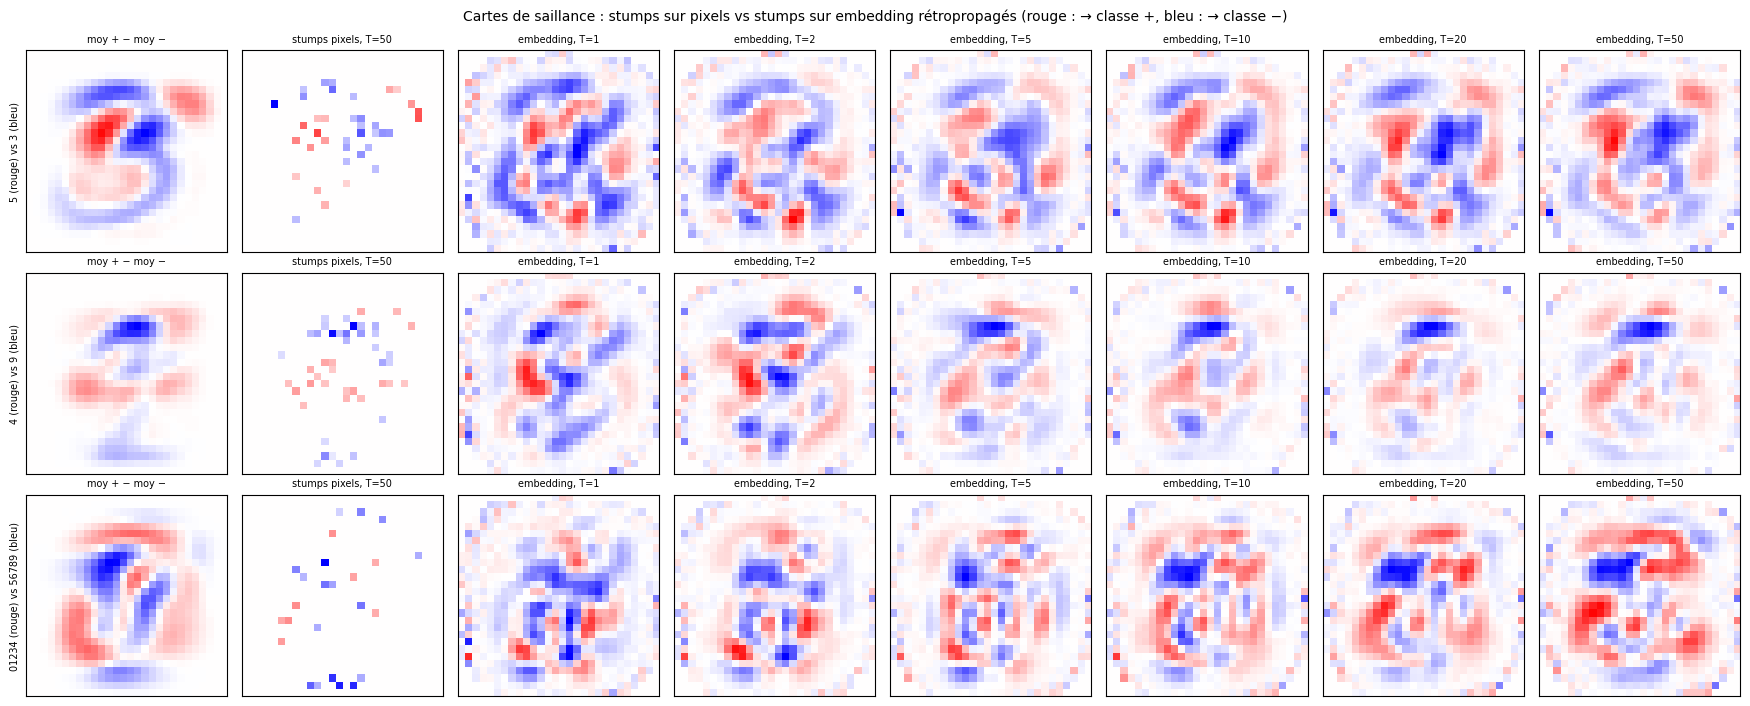

In [226]:
def afficher(ax, carte, titre):
    m = np.abs(carte).max() + 1e-12
    ax.imshow(carte, cmap="bwr", vmin=-m, vmax=m)
    ax.set_title(titre, fontsize=7)
    ax.set_xticks([]); ax.set_yticks([])

paires = [([5], [3]), ([4], [9]), ([0, 1, 2, 3, 4], [5, 6, 7, 8, 9])]
Ts = [1, 2, 5, 10, 20, 50]
T_MAX = max(Ts)

fig, axes = plt.subplots(len(paires), 2 + len(Ts), figsize=(2.2 * (2 + len(Ts)), 2.4 * len(paires)))

for i, (plus, moins) in enumerate(paires):
    # 1) on garde seulement les images des deux classes
    masque = np.isin(y_train_FR, plus + moins)
    X_p, E_p = X_train_FR[masque], E_train_FR[masque]
    y_p = np.isin(y_train_FR[masque], plus).astype(int)          # 1 = classe +, 0 = classe -
    nom = f"{''.join(map(str, plus))} (rouge) vs {''.join(map(str, moins))} (bleu)"

    # 2) colonne 1 : image moyenne de la classe + moins image moyenne de la classe -
    diff = X_p[y_p == 1].mean(axis=0) - X_p[y_p == 0].mean(axis=0)
    afficher(axes[i, 0], diff.reshape(28, 28), "moy + − moy −")
    axes[i, 0].set_ylabel(nom, fontsize=7)

    # 3) colonne 2 : stumps sur pixels (un seul modèle de 200 stumps)
    ada_pix = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                 n_estimators=T_MAX, random_state=seed).fit(X_p, y_p)
    afficher(axes[i, 1], carte_pixels(ada_pix, T_MAX), f"stumps pixels, T={T_MAX}")

    # 4) colonnes suivantes : stumps sur l'embedding, on ne garde que les T premiers stumps
    ada_emb = AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                 n_estimators=T_MAX, random_state=seed).fit(E_p, y_p)
    for k, T in enumerate(Ts):
        afficher(axes[i, 2 + k], carte_embedding(ada_emb, T, E_p), f"embedding, T={T}")

fig.suptitle("Cartes de saillance : stumps sur pixels vs stumps sur embedding rétropropagés "
             "(rouge : → classe +, bleu : → classe −)", fontsize=10)
fig.tight_layout()
plt.savefig("images/saillance_map/saillance_embedding.png", dpi=300, bbox_inches="tight")
plt.show()

<img src="images/saillance_map/saillance_embedding.png" alt= "Matrice de confusion décision stump" width="1200">